# Talos - AC Setting Recommender

In Assignment 2 we wrote rules by hand (R1, R2, R3) to control the AC. Here we try to let a model **learn the user's routine from the data**: given the room condition and the time, what AC setting does the user want? (off, 16C, 19C, 20C or 21C)

This is a classification problem. We use a Random Forest Classifier with most of our columns, and then compare it with our Assignment 2 rules on the same data.

Run `00_preprocessing.ipynb` first, it makes `data_1min.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

## 1. Load the per-minute data

In [2]:
m = pd.read_csv('data_1min.csv', parse_dates=['pc_time'], index_col='pc_time', dtype={'ac_setting': str})
m['ac_setting'].value_counts()

ac_setting
21C    2561
off    2447
16C    1933
19C     272
20C     196
18C       2
Name: count, dtype: int64

## 2. Clean up the labels

17 and 18 only show up for a few seconds while the user is pressing the remote down from 21 to 16, so they're not a real choice. We remove those minutes.

In [3]:
m = m[~m['ac_setting'].isin(['17C', '18C'])].copy()
m['ac_setting'].value_counts()

ac_setting
21C    2561
off    2447
16C    1933
19C     272
20C     196
Name: count, dtype: int64

## 3. Features

We use a lot of the columns here:
- `temp_c`, `humidity_pct`: room condition now
- `temp_change_5m`, `temp_30m_ago`: is the room heating up or cooling down
- `mic_median_5m`, `occupied`: is someone there
- `hour_sin`, `hour_cos`: time of day (we use sin/cos so 23:00 and 00:00 are close to each other)
- `weekday`: day of the week

We do **not** give the model the current AC state, otherwise it would just copy it.

In [4]:
m['hour_sin'] = np.sin(2 * np.pi * m['hour'] / 24)
m['hour_cos'] = np.cos(2 * np.pi * m['hour'] / 24)

FEATURES = ['temp_c', 'humidity_pct', 'temp_change_5m', 'temp_30m_ago',
            'mic_median_5m', 'occupied', 'hour_sin', 'hour_cos', 'weekday']
data = m.dropna(subset=FEATURES + ['ac_setting'])
X = data[FEATURES]
y = data['ac_setting']
print(len(data), 'rows')

7379 rows


## 4. Train / test split

Same as the forecast: no shuffling, first 80% train, last 20% test.

In [5]:
split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print('train:', X_train.index.min(), 'to', X_train.index.max())
print('test :', X_test.index.min(), 'to', X_test.index.max())
print(y_test.value_counts().to_dict())

train: 2026-11-05 20:59:00 to 2026-11-09 23:23:00
test : 2026-11-09 23:24:00 to 2026-11-10 23:59:00
{'off': 653, '21C': 500, '16C': 230, '19C': 57, '20C': 36}


## 5. Train the model

In [6]:
model = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)
confidence = model.predict_proba(X_test).max(axis=1)

## 6. Evaluate

In [7]:
print('Accuracy :', round(accuracy_score(y_test, pred), 3))
print('F1 (macro):', round(f1_score(y_test, pred, average='macro'), 3))
print()
print(classification_report(y_test, pred, zero_division=0))

Accuracy : 0.928
F1 (macro): 0.757

              precision    recall  f1-score   support

         16C       0.96      0.85      0.90       230
         19C       0.39      0.86      0.53        57
         20C       0.43      0.36      0.39        36
         21C       0.99      0.92      0.96       500
         off       1.00      1.00      1.00       653

    accuracy                           0.93      1476
   macro avg       0.75      0.80      0.76      1476
weighted avg       0.95      0.93      0.94      1476



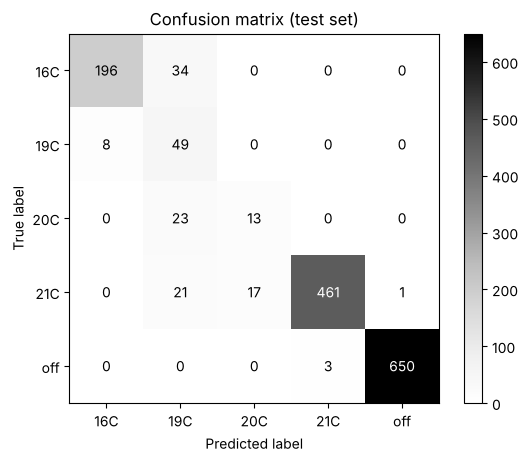

In [8]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Greys')
plt.title('Confusion matrix (test set)')
plt.show()

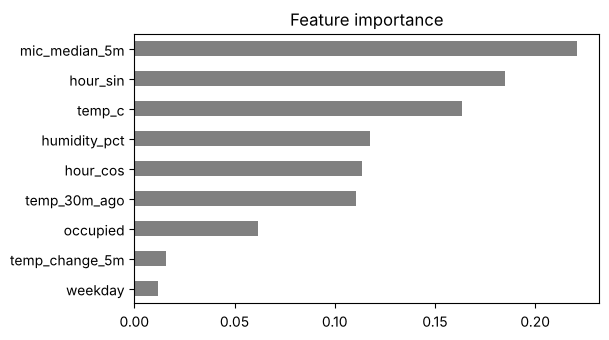

In [9]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind='barh', color='gray', figsize=(6, 3.5), title='Feature importance')
plt.show()

### Confidence

In real time we only want Talos to act when the model is sure. Here we check how accurate it is when the confidence is above 80%.

In [10]:
sure = confidence >= 0.8
print(f'{sure.mean():.0%} of the test minutes have confidence >= 80%')
print('accuracy on those:', round(accuracy_score(y_test[sure], pred[sure]), 3))

90% of the test minutes have confidence >= 80%
accuracy on those: 0.979


## 7. Compare with our Assignment 2 rules

Here we replay a simple version of R1, R2 and R3 on the same test data, minute by minute, and see how often the rules end up at the same setting as the user. (R4 and R5 are left out to keep it simple.)

In [11]:
def replay_rules(d):
    state = 'off'
    last_change = None
    occ_since = d.index[0]
    prev_occ = d['occupied'].iloc[0]
    out = []
    for t, r in d.iterrows():
        if r['occupied'] != prev_occ:
            occ_since, prev_occ = t, r['occupied']
        held = (t - occ_since).total_seconds() / 60
        sp = None if state == 'off' else int(state[:-1])
        # R1: AC on and empty for 15 min -> off
        if sp and not r['occupied'] and held >= 15:
            state, last_change = 'off', t
        # R2: AC off, occupied 2 min, temp >= 26 -> 16
        elif sp is None and r['occupied'] and held >= 2 and r['temp_c'] >= 26:
            state, last_change = '16C', t
        # R3: night, room cooled, humidity ok, 30 min since last change -> raise
        elif sp and sp < 21 and (t.hour >= 23 or t.hour < 3) and r['humidity_pct'] <= 66 \
                and r['temp_c'] <= 20.9 + 0.32 * (sp - 16) + 0.2 \
                and (last_change is None or (t - last_change).total_seconds() >= 1800):
            state, last_change = str(19 if sp < 19 else sp + 1) + 'C', t
        out.append(state)
    return pd.Series(out, index=d.index)

test = data.iloc[split:]
rule_pred = replay_rules(test)

pd.DataFrame([
    {'method': 'Assignment 2 rules (R1-R3)', 'accuracy': round(accuracy_score(y_test, rule_pred), 3),
     'F1 (macro)': round(f1_score(y_test, rule_pred, average='macro'), 3)},
    {'method': 'Random Forest', 'accuracy': round(accuracy_score(y_test, pred), 3),
     'F1 (macro)': round(f1_score(y_test, pred, average='macro'), 3)},
])

,method,accuracy,F1 (macro)
0,Assignment 2 rules (R1-R3),0.571,0.320
1,Random Forest,0.928,0.757


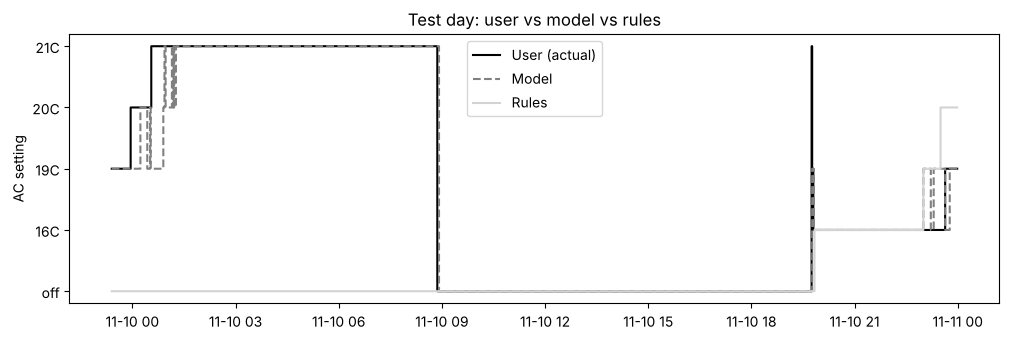

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.5))
order = ['off', '16C', '19C', '20C', '21C']
to_num = {k: i for i, k in enumerate(order)}
ax.step(y_test.index, y_test.map(to_num), where='post', color='black', label='User (actual)')
ax.step(y_test.index, pd.Series(pred, index=y_test.index).map(to_num), where='post', color='gray', linestyle='--', label='Model')
ax.step(y_test.index, rule_pred.map(to_num), where='post', color='lightgray', label='Rules')
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_ylabel('AC setting')
ax.legend()
plt.title('Test day: user vs model vs rules')
plt.show()

## 8. Save the model

In [13]:
joblib.dump({'model': model, 'features': FEATURES}, 'ac_recommender_model.pkl')
print('saved ac_recommender_model.pkl')

saved ac_recommender_model.pkl


## 9. Try it with one situation

Evening, the room is hot and someone is there.

In [14]:
hour = 20
now = pd.DataFrame([{
    'temp_c': 28.0, 'humidity_pct': 72, 'temp_change_5m': 0.1, 'temp_30m_ago': 27.8,
    'mic_median_5m': 45000, 'occupied': 1,
    'hour_sin': np.sin(2 * np.pi * hour / 24), 'hour_cos': np.cos(2 * np.pi * hour / 24), 'weekday': 2,
}])
p = model.predict_proba(now[FEATURES])[0]
best = model.classes_[p.argmax()]
print('Recommended AC setting:', best, f'(confidence {p.max():.0%})')

Recommended AC setting: 16C (confidence 66%)


## How we're going to use this in Talos (real time)

**Purpose:** let Talos learn the user's own AC routine from the data, instead of us writing every rule by hand. This one model covers what R1, R2 and R3 did separately (turn on, start cold, raise at night, turn off in the morning).

**How it runs:**
1. The Python script that listens to `talos/readings` builds the same features once per minute.
2. It loads `ac_recommender_model.pkl` and gets the recommended setting (off / 16C / 19C / 20C / 21C) and the **confidence** (the highest probability from `predict_proba`).
3. It sends `recommended_ac` and `confidence` to ThingsBoard, so the dashboard shows the suggestion, how sure the model is, and a history of the suggestions next to the real AC state.
4. If the confidence is high (for example above 80%) **and** the suggestion is different from the current AC state **and** the last command was more than 10 minutes ago, it sends the command to the board. The board sends the IR frame to the AC and the speaker announces it, just like in Assignment 2.
5. The safety rules from Assignment 2 stay on the board: if the user uses the real remote, the automation still pauses for 60 minutes (R4), and the 10-minute gap (R5) still applies.

When the confidence is low, Talos doesn't do anything and just keeps the current setting.